# Malmö Data Preparation

This notebook prepares geospatial inputs for an urban-heat analysis: UTCI scenario rasters, a Malmö boundary mask, land-cover predictors, and temperature rasters derived from ERA5 and SMHI data. The sections cover separate preparation stages; check the paths and settings in each cell, and run prerequisite cells before cells that reuse their variables.

## Data Sources and Licences

### Malmö Open Data

Source: [opendata.malmo.se](https://opendata.malmo.se/)
According to the data portal, its open data may be freely used, modified, and shared by private individuals and private and public organizations. For some datasets explicit Licenses are given.

Municipal datasets are used to represent relevant urban characteristics.
- [Heat maps](https://opendata.malmo.se/en/@malmo/varmekarteringar) (Creative Commons CCZero): entails the UTCI modelled based on a [SOLWEIG model](https://umep-docs.readthedocs.io/en/latest/OtherManuals/SOLWEIG.html) 
- [The primary map](https://opendata.malmo.se/en/%40malmo/primarkartan) (cc0-1.0): here utilized: Buildings.geojson.
- [Tree canopy](https://opendata.malmo.se/en/%40malmo/tradkrontackning-2022)(no License given): proportion of the city covered by greenery.
- [Landsurface](https://opendata.malmo.se/en/@malmo/varmekarteringar) (no License given): The following layers were used: Residential areas, Paved and artificial surfaces, Industrial areas, Cemeteries, Natural areas, Parks and green spaces, Open land, Special recreational areas, Plot and property land, Water bodies


In [ ]:
from pathlib import Path

# Project data directory and source layers for the feature-preparation workflow.
BASE = Path("C:\\Users\\clara\\OneDrive\\Dokumente\\Studium\\Lund\\Reproducibility\\bern-02\\final_project\\data")

# Target raster and vector inputs.
TARGET = BASE / "UTCI_DayAverage.tiff"
BUILDINGS = BASE / "buildings.geojson"
CANOPY = BASE / "tree_canopy2m.gpkg"
LANDCOVER = BASE / "landuse_3006.gpkg"


# Malm? boundary and output folder for aligned layers.
BOUNDARY = BASE / "stadsomraden_3006.gpkg"

OUT = BASE / "processed_5m"
OUT.mkdir(parents=True, exist_ok=True)

## 1. Extract UTCI scenario rasters

Match each ZIP archive to a scenario name, then extract only its `UTCI_DayAverage.tiff` into `data/utci_scenarios`. Unmatched archives are skipped, and extraction failures are listed in the summary.

In [ ]:

from pathlib import Path
from zipfile import ZipFile
import shutil

# ============================================================
# 1. PATHS — EDIT THESE
# ============================================================

ZIP_DIR = Path(
    r"C:\Users\clara\OneDrive\Dokumente\Studium\Lund"
    r"\Reproducibility\bern-02\Final Project\data\utci_zips"
)

OUT_DIR = Path(
    r"C:\Users\clara\OneDrive\Dokumente\Studium\Lund"
    r"\Reproducibility\bern-02\Final Project\data\utci_scenarios"
)

OUT_DIR.mkdir(parents=True, exist_ok=True)

# ============================================================
# 2. ZIP FILES AND OUTPUT NAMES
# Keys are matched against ZIP filenames, case-insensitively.
# ============================================================

SCENARIOS = {
    "01_1994-07-26-nutid": "1994-07-26_UTCI_present_hot.tif",
    "02_2022-06-24-nutid": "2022-06-24_UTCI_current.tif",
    "03_1994-07-26-rcp85-2050": "1994-07-26_UTCI_RCP85_2050.tif",
    "04_1994-07-26-rcp85-2100": "1994-07-26_UTCI_RCP85_2100.tif",
    "05_1994-07-26-rcp45-2050": "1994-07-26_UTCI_RCP45_2050.tif",
    "06_1994-07-26-rcp45-2100": "1994-07-26_UTCI_RCP45_2100.tif",
    "07_2022-06-24-rcp85-2050": "2022-06-24_UTCI_RCP85_2050.tif",
    "08_2022-06-24-rcp85-2100": "2022-06-24_UTCI_RCP85_2100.tif",
    "09_2022-06-24-rcp45-2050": "2022-06-24_UTCI_RCP45_2050.tif",
    "10_2022-06-24-rcp45-2100": "2022-06-24_UTCI_RCP45_2100.tif",
}

# ============================================================
# 3. EXTRACT UTCI TIFF FROM EACH ZIP
# ============================================================

zip_files = sorted(ZIP_DIR.glob("*.zip"))

if not zip_files:
    raise FileNotFoundError(f"No ZIP files found in {ZIP_DIR}")

success = []
failed = []

for zip_path in zip_files:
    zip_stem = zip_path.stem.lower()

    # Find the scenario matching this ZIP filename.
    output_name = next(
        (
            filename
            for scenario_key, filename in SCENARIOS.items()
            if scenario_key.lower() in zip_stem
        ),
        None,
    )

    if output_name is None:
        print(f"SKIPPED — ZIP filename not in scenario list: {zip_path.name}")
        continue

    output_path = OUT_DIR / output_name

    try:
        with ZipFile(zip_path, "r") as z:
            # Search nested folders for the requested TIFF.
            matches = [
                member
                for member in z.namelist()
                if Path(member).name.lower() == "utci_dayaverage.tiff"
            ]

            if not matches:
                raise FileNotFoundError(
                    "UTCI_Day_Average.tif not found inside ZIP"
                )

            if len(matches) > 1:
                print(
                    f"WARNING — {zip_path.name} contains "
                    f"{len(matches)} matching TIFFs; using {matches[0]}"
                )

            # Extract only the selected TIFF, not the entire ZIP.
            with z.open(matches[0]) as source, open(output_path, "wb") as dest:
                shutil.copyfileobj(source, dest)

        success.append(output_path)
        print(f"SAVED: {zip_path.name} -> {output_path.name}")

    except Exception as exc:
        failed.append((zip_path.name, str(exc)))
        print(f"FAILED: {zip_path.name}: {exc}")

# ============================================================
# 4. SUMMARY
# ============================================================

print("\nFinished.")
print(f"Successfully extracted: {len(success)}")
print(f"Failed: {len(failed)}")
print(f"Output folder: {OUT_DIR}")

if failed:
    print("\nFiles needing attention:")
    for filename, error in failed:
        print(f" - {filename}: {error}")


## 2. Resample scenarios to 5 m

Resample each extracted UTCI GeoTIFF to a 5 m grid using average aggregation. The output keeps the source CRS and extent and is saved under `utci_scen_5m`.

In [ ]:
from pathlib import Path
import math

import rasterio
from rasterio.enums import Resampling
from rasterio.transform import from_origin
from rasterio.warp import reproject

# --------------------------------------------------
# 1. Paths and settings
# --------------------------------------------------
BASE = Path(
    r"C:\Users\clara\OneDrive\Dokumente\Studium\Lund\Reproducibility\bern-02\final_project\data\utci_scenarios"
)

OUT = BASE / "utci_scen_5m"
OUT.mkdir(parents=True, exist_ok=True)

RESOLUTION = 5.0  # metres
NODATA = -9999.0

# --------------------------------------------------
# 2. Find every UTCI raster in BASE
# --------------------------------------------------
extensions = {".tif", ".tiff"}

utci_files = sorted(
    p for p in BASE.iterdir()
    if p.is_file()
    and p.suffix.lower() in extensions
    and "utci" in p.stem.lower()
)

if not utci_files:
    raise FileNotFoundError(
        f"No UTCI GeoTIFF files found in {BASE}"
    )

print(f"Found {len(utci_files)} UTCI files.")

# --------------------------------------------------
# 3. Process each UTCI file
# --------------------------------------------------
for i, input_path in enumerate(utci_files, start=1):

    output_path = OUT / f"{input_path.stem}_5m.tif"

    print(
        f"\n[{i}/{len(utci_files)}] "
        f"Processing: {input_path.name}"
    )

    try:
        with rasterio.open(input_path) as src:

            if src.crs is None:
                print("  Skipped: raster has no CRS.")
                continue

            bounds = src.bounds
            target_crs = src.crs

            # Define a 5 m grid from this UTCI file
            width = math.ceil(
                (bounds.right - bounds.left) / RESOLUTION
            )
            height = math.ceil(
                (bounds.top - bounds.bottom) / RESOLUTION
            )

            transform = from_origin(
                bounds.left,
                bounds.top,
                RESOLUTION,
                RESOLUTION,
            )

            profile = {
                "driver": "GTiff",
                "width": width,
                "height": height,
                "count": 1,
                "dtype": "float32",
                "crs": target_crs,
                "transform": transform,
                "nodata": NODATA,
                "compress": "deflate",
                "predictor": 3,
                "tiled": True,
                "BIGTIFF": "IF_SAFER",
            }

            with rasterio.open(
                output_path, "w", **profile
            ) as dst:

                reproject(
                    source=rasterio.band(src, 1),
                    destination=rasterio.band(dst, 1),
                    src_transform=src.transform,
                    src_crs=src.crs,
                    src_nodata=src.nodata,
                    dst_transform=transform,
                    dst_crs=target_crs,
                    dst_nodata=NODATA,
                    resampling=Resampling.average,
                )

        print(f"  Saved: {output_path.name}")

    except Exception as exc:
        print(f"  ERROR: {input_path.name}: {exc}")

print("\nAll UTCI files processed.")
print(f"Outputs saved to: {OUT}")



Found 10 UTCI files.

[1/10] Processing: 1994-07-26_UTCI_present_hot.tif
  Saved: 1994-07-26_UTCI_present_hot_5m.tif

[2/10] Processing: 1994-07-26_UTCI_RCP45_2050.tif
  Saved: 1994-07-26_UTCI_RCP45_2050_5m.tif

[3/10] Processing: 1994-07-26_UTCI_RCP45_2100.tif
  Saved: 1994-07-26_UTCI_RCP45_2100_5m.tif

[4/10] Processing: 1994-07-26_UTCI_RCP85_2050.tif
  Saved: 1994-07-26_UTCI_RCP85_2050_5m.tif

[5/10] Processing: 1994-07-26_UTCI_RCP85_2100.tif
  Saved: 1994-07-26_UTCI_RCP85_2100_5m.tif

[6/10] Processing: 2022-06-24_UTCI_current.tif
  Saved: 2022-06-24_UTCI_current_5m.tif

[7/10] Processing: 2022-06-24_UTCI_RCP45_2050.tif
  Saved: 2022-06-24_UTCI_RCP45_2050_5m.tif

[8/10] Processing: 2022-06-24_UTCI_RCP45_2100.tif
  Saved: 2022-06-24_UTCI_RCP45_2100_5m.tif

[9/10] Processing: 2022-06-24_UTCI_RCP85_2050.tif
  Saved: 2022-06-24_UTCI_RCP85_2050_5m.tif

[10/10] Processing: 2022-06-24_UTCI_RCP85_2100.tif
  Saved: 2022-06-24_UTCI_RCP85_2100_5m.tif

All UTCI files processed.
Outputs saved t

## 3. Mask scenarios to Malmö

Combine valid stadsomr?den geometries and mask each resampled raster to their union. Pixels outside the boundary, as well as existing invalid/NoData pixels, receive the explicit NoData value `-9999`.

In [ ]:
from pathlib import Path

import numpy as np
import geopandas as gpd
import rasterio
from rasterio.features import geometry_mask
from shapely.ops import unary_union

# --------------------------------------------------
# 1. Paths and settings
# --------------------------------------------------
DATA = Path(
    r"C:\Users\clara\OneDrive\Dokumente\Studium\Lund\Reproducibility\bern-02\final_project\data"
)

BOUNDARY_PATH = DATA / "stadsomraden_3006.gpkg"
UTCI_DIR = DATA / "utci_scenarios" / "utci_scen_5m"

MASKED_DIR = UTCI_DIR / "utci_5m_masked"
MASKED_DIR.mkdir(parents=True, exist_ok=True)

NODATA_VALUE = -9999.0

# --------------------------------------------------
# 2. Load stadsområden and combine their geometries
# --------------------------------------------------
areas = gpd.read_file(BOUNDARY_PATH)

if areas.crs is None:
    raise ValueError(
        "The stadsområden layer has no CRS defined."
    )

print("Boundary CRS:", areas.crs)
print("Number of stadsområden:", len(areas))

areas = areas[
    areas.geometry.notna() & ~areas.geometry.is_empty
].copy()

# Repair invalid geometries where possible
areas.geometry = areas.geometry.make_valid()

# Remove any empty geometries after repair
areas = areas[
    areas.geometry.notna() & ~areas.geometry.is_empty
].copy()

if areas.empty:
    raise ValueError("No valid boundary geometries found.")

# Combine all stadsområden into one geometry
boundary = unary_union(areas.geometry)

# --------------------------------------------------
# 3. Find every processed UTCI raster
# --------------------------------------------------
utci_files = sorted(
    p for p in UTCI_DIR.iterdir()
    if p.is_file()
    and p.suffix.lower() in {".tif", ".tiff"}
    and "utci" in p.stem.lower()
    and "_malmo_boundary" not in p.stem.lower()
)

if not utci_files:
    raise FileNotFoundError(
        f"No UTCI rasters found in {UTCI_DIR}"
    )

print(f"Found {len(utci_files)} UTCI rasters.")

# --------------------------------------------------
# 4. Mask every UTCI raster to Malmö's boundary
# --------------------------------------------------
for i, utci_path in enumerate(utci_files, start=1):

    masked_path = (
        MASKED_DIR /
        f"{utci_path.stem}_malmo_boundary.tif"
    )

    print(
        f"\n[{i}/{len(utci_files)}] "
        f"Processing: {utci_path.name}"
    )

    try:
        with rasterio.open(utci_path) as src:

            if src.crs is None:
                print("  Skipped: raster has no CRS.")
                continue

            # Reproject boundary to match this raster
            raster_areas = areas.to_crs(src.crs)
            raster_boundary = unary_union(
                raster_areas.geometry
            )

            utci = src.read(1)
            profile = src.profile.copy()

            # Pixels whose centres fall inside the boundary
            inside = geometry_mask(
                [raster_boundary],
                out_shape=src.shape,
                transform=src.transform,
                invert=True,
                all_touched=False,
            )

            # Respect existing NoData values
            valid = np.isfinite(utci)

            if src.nodata is not None:
                valid &= utci != src.nodata

            valid &= inside

            # Convert output to float32 to store explicit NoData
            masked_utci = utci.astype(np.float32)
            masked_utci[~valid] = NODATA_VALUE

            profile.update(
                dtype="float32",
                count=1,
                nodata=NODATA_VALUE,
                compress="deflate",
            )

            with rasterio.open(
                masked_path, "w", **profile
            ) as dst:
                dst.write(masked_utci, 1)

        print(f"  Saved: {masked_path.name}")
        print("  Valid pixels inside boundary:", int(valid.sum()))
        print(
            "  Outside boundary or invalid:",
            int((~valid).sum()),
        )

    except Exception as exc:
        print(f"  ERROR processing {utci_path.name}: {exc}")

print("\nAll UTCI rasters processed.")
print(f"Masked outputs saved in: {MASKED_DIR}")


c:\Users\clara\anaconda3\envs\cnn_course\Lib\site-packages\pyogrio\raw.py:200: UserWarning: Measured (M) geometry types are not supported. Original type 'Measured 3D MultiPolygon' is converted to 'MultiPolygon Z'
  return ogr_read(


Boundary CRS: EPSG:3006
Number of stadsområden: 5
Found 10 UTCI rasters.

[1/10] Processing: 1994-07-26_UTCI_present_hot_5m.tif
  Saved: 1994-07-26_UTCI_present_hot_5m_malmo_boundary.tif
  Valid pixels inside boundary: 5537908
  Outside boundary or invalid: 5002468

[2/10] Processing: 1994-07-26_UTCI_RCP45_2050_5m.tif
  Saved: 1994-07-26_UTCI_RCP45_2050_5m_malmo_boundary.tif
  Valid pixels inside boundary: 5537908
  Outside boundary or invalid: 5002468

[3/10] Processing: 1994-07-26_UTCI_RCP45_2100_5m.tif
  Saved: 1994-07-26_UTCI_RCP45_2100_5m_malmo_boundary.tif
  Valid pixels inside boundary: 5537908
  Outside boundary or invalid: 5002468

[4/10] Processing: 1994-07-26_UTCI_RCP85_2050_5m.tif
  Saved: 1994-07-26_UTCI_RCP85_2050_5m_malmo_boundary.tif
  Valid pixels inside boundary: 5537908
  Outside boundary or invalid: 5002468

[5/10] Processing: 1994-07-26_UTCI_RCP85_2100_5m.tif
  Saved: 1994-07-26_UTCI_RCP85_2100_5m_malmo_boundary.tif
  Valid pixels inside boundary: 5537908
  Outside

## 4. Inspect the boundary mask

Plot the original and masked rasters side by side with the stadsomraden outline. This cell expects `UTCI_PATH`, `MASKED_PATH`, `BOUNDARY_PATH`, and `raster_crs` to be set by the preceding analysis context.

c:\Users\clara\anaconda3\envs\cnn_course\Lib\site-packages\pyogrio\raw.py:200: UserWarning: Measured (M) geometry types are not supported. Original type 'Measured 3D MultiPolygon' is converted to 'MultiPolygon Z'
  return ogr_read(


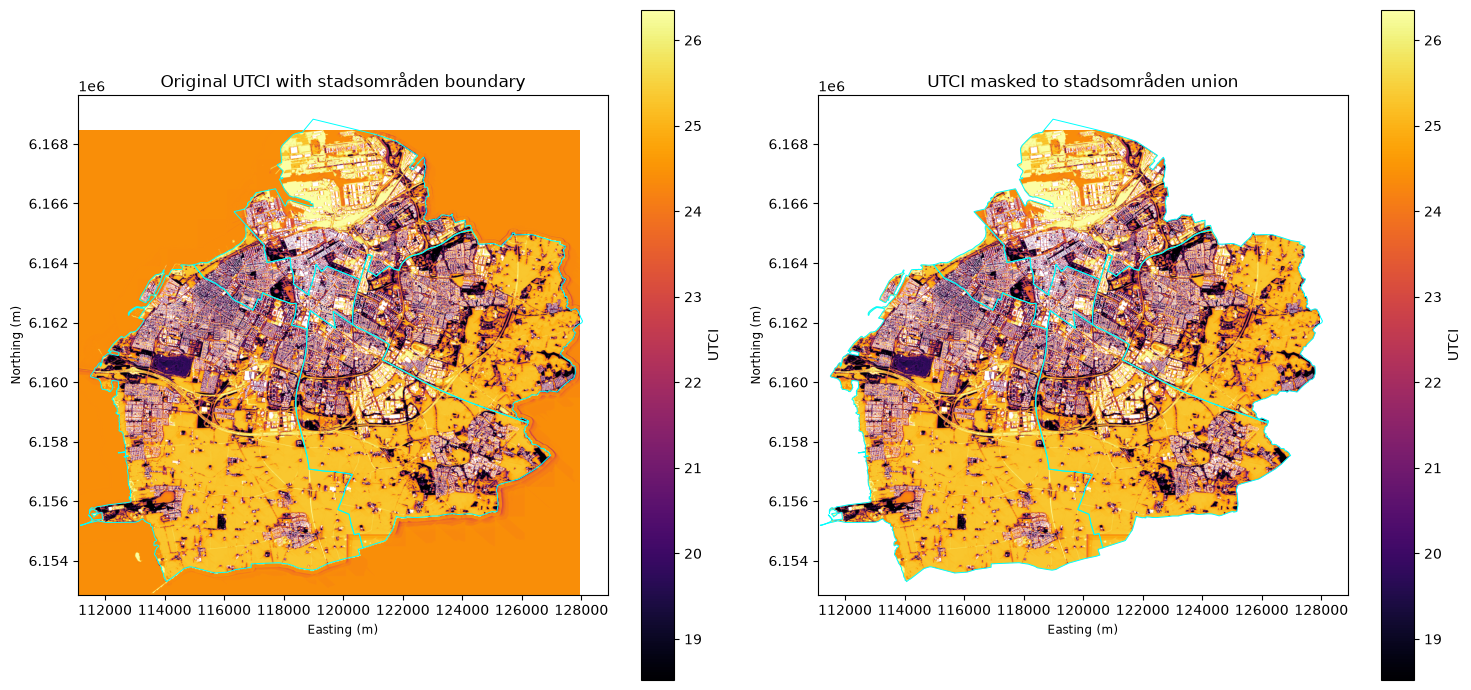

In [3]:

import matplotlib.pyplot as plt
import rasterio
import geopandas as gpd
import numpy as np

# Compare the original raster with its masked version on a shared colour scale.
with rasterio.open(UTCI_PATH) as src:
    original = src.read(1).astype(np.float32)
    bounds = src.bounds
    original_nodata = src.nodata

if original_nodata is not None:
    original[original == original_nodata] = np.nan

with rasterio.open(MASKED_PATH) as src:
    masked = src.read(1).astype(np.float32)
    masked[masked == src.nodata] = np.nan
    extent = [bounds.left, bounds.right, bounds.bottom, bounds.top]

# Reproject the boundary so its outline aligns with the raster coordinates.
boundary_plot = gpd.read_file(BOUNDARY_PATH).to_crs(raster_crs)

fig, axes = plt.subplots(1, 2, figsize=(15, 7))

# Percentile limits reduce the influence of extreme values in the display.
vmin = np.nanpercentile(masked, 2)
vmax = np.nanpercentile(masked, 98)

im0 = axes[0].imshow(
    original, extent=extent, origin="upper",
    cmap="inferno", vmin=vmin, vmax=vmax
)
boundary_plot.boundary.plot(ax=axes[0], color="cyan", linewidth=0.7)
axes[0].set_title("Original UTCI with stadsområden boundary")
fig.colorbar(im0, ax=axes[0], label="UTCI")

im1 = axes[1].imshow(
    masked, extent=extent, origin="upper",
    cmap="inferno", vmin=vmin, vmax=vmax
)
boundary_plot.boundary.plot(ax=axes[1], color="cyan", linewidth=0.7)
axes[1].set_title("UTCI masked to stadsområden union")
fig.colorbar(im1, ax=axes[1], label="UTCI")

for ax in axes:
    ax.set_xlabel("Easting (m)")
    ax.set_ylabel("Northing (m)")
    ax.set_aspect("equal")

plt.tight_layout()
plt.show()


## 5. Build the target grid and predictor rasters

Create aligned 5 m rasters for UTCI, building presence, tree canopy, and land-use classes. The target raster defines the shared extent and coordinate reference system; binary predictor layers are written to `data/processed_5m`.

In [ ]:

from pathlib import Path
import re
import math

import numpy as np
import geopandas as gpd
import rasterio
from rasterio.enums import Resampling
from rasterio.features import rasterize
from rasterio.transform import from_origin
from rasterio.warp import reproject

# --------------------------------------------------
# 1. Paths and settings
# --------------------------------------------------
BASE = Path(
    r"C:\Users\clara\OneDrive\Dokumente\Studium\Lund"
    r"\Reproducibility\bern-02\final_project\data"
)

TARGET = BASE / "UTCI_DayAverage.tiff"
BUILDINGS = BASE / "buildings.geojson"
CANOPY = BASE / "tree_canopy2m.gpkg"
LANDCOVER = BASE / "landuse_3006.gpkg"

OUT = BASE / "processed_5m"
OUT.mkdir(parents=True, exist_ok=True)

RESOLUTION = 5.0  # metres
DTYPE = "uint8"

# --------------------------------------------------
# 2. Define a 10 m grid from the target raster
# --------------------------------------------------
with rasterio.open(TARGET) as src:
    target_crs = src.crs
    bounds = src.bounds

    if src.crs is None:
        raise ValueError("The target raster has no CRS.")

    # Round dimensions up so the full target extent is covered.
    width = math.ceil((bounds.right - bounds.left) / RESOLUTION)
    height = math.ceil((bounds.top - bounds.bottom) / RESOLUTION)

    transform = from_origin(
        bounds.left, bounds.top, RESOLUTION, RESOLUTION
    )

    profile = {
        "driver": "GTiff",
        "width": width,
        "height": height,
        "count": 1,
        "dtype": "float32",
        "crs": target_crs,
        "transform": transform,
        "nodata": -9999.0,
        "compress": "deflate",
        "predictor": 3,
        "tiled": True,
        "BIGTIFF": "IF_SAFER",
    }

print("Target CRS:", target_crs)
print("5 m grid:", width, "columns x", height, "rows")
print("Output pixels:", width * height)

# --------------------------------------------------
# 3. Aggregate UTCI to the 10 m grid
#    Reprojects/resamples directly from the source file.
# --------------------------------------------------
utci_path = OUT / "utci_mean_5m.tif"

with rasterio.open(TARGET) as src:
    with rasterio.open(utci_path, "w", **profile) as dst:
        reproject(
            source=rasterio.band(src, 1),
            destination=rasterio.band(dst, 1),
            src_transform=src.transform,
            src_crs=src.crs,
            src_nodata=src.nodata,
            dst_transform=transform,
            dst_crs=target_crs,
            dst_nodata=-9999.0,
            resampling=Resampling.average,
        )

# Valid-target mask: 1 = valid UTCI cell, 0 = invalid.
valid_path = OUT / "valid_target_5m.tif"

with rasterio.open(utci_path) as src:
    utci = src.read(1)
    valid = np.isfinite(utci) & (utci != -9999.0)

    mask_profile = profile.copy()
    mask_profile.update(dtype="uint8", nodata=0, predictor=2)

    with rasterio.open(valid_path, "w", **mask_profile) as dst:
        dst.write(valid.astype("uint8"), 1)

del utci, valid
print("Saved UTCI target and validity mask.")

# --------------------------------------------------
# 4. Helper: reproject vectors and rasterize them
# --------------------------------------------------
def read_projected(path):
    gdf = gpd.read_file(path)

    if gdf.crs is None:
        raise ValueError(f"{path.name} has no CRS defined.")

    gdf = gdf.to_crs(target_crs)
    gdf = gdf[gdf.geometry.notna() & ~gdf.geometry.is_empty]

    # Remove invalid geometries where possible.
    invalid = ~gdf.geometry.is_valid
    if invalid.any():
        gdf.loc[invalid, "geometry"] = (
            gdf.loc[invalid, "geometry"].make_valid()
        )

    # Keep only geometries intersecting the target area.
    from shapely.geometry import box
    extent = box(bounds.left, bounds.bottom, bounds.right, bounds.top)
    gdf = gdf[gdf.geometry.intersects(extent)]

    return gdf


def burn_binary(gdf, output_path):
    """Create a 10 m raster: 1 where a feature is present, otherwise 0."""
    shapes = (
        (geom, 1)
        for geom in gdf.geometry
        if geom is not None and not geom.is_empty
    )

    arr = rasterize(
        shapes=shapes,
        out_shape=(height, width),
        transform=transform,
        fill=0,
        dtype=DTYPE,
        all_touched=False,
    )

    out_profile = profile.copy()
    out_profile.update(dtype=DTYPE, nodata=0, predictor=2)

    with rasterio.open(output_path, "w", **out_profile) as dst:
        dst.write(arr, 1)

    print(f"Saved {output_path.name}")


# --------------------------------------------------
# 5. Buildings
# --------------------------------------------------
buildings = read_projected(BUILDINGS)
print("Buildings intersecting target:", len(buildings))

burn_binary(
    buildings,
    OUT / "building_presence_10m.tif"
)

del buildings

# --------------------------------------------------
# 6. Tree canopy
# --------------------------------------------------
canopy = read_projected(CANOPY)
print("Canopy polygons intersecting target:", len(canopy))

burn_binary(
    canopy,
    OUT / "canopy_presence_10m.tif"
)

del canopy

# --------------------------------------------------
# 7. Land-use: one binary raster per class
# --------------------------------------------------
landuse = read_projected(LANDCOVER)
print("Land-use polygons intersecting target:", len(landuse))
print("Land-use classes:", sorted(landuse["typ"].dropna().unique()))

for land_class in sorted(landuse["typ"].dropna().unique()):
    subset = landuse[landuse["typ"] == land_class]

    # Create filesystem-friendly filenames.
    safe_name = re.sub(
        r"[^a-zA-Z0-9_-]+", "_", str(land_class)
    ).strip("_").lower()

    output_path = OUT / f"landuse_{safe_name}_10m.tif"

    burn_binary(subset, output_path)

del landuse

print("\nPreprocessing finished.")
print("Files saved in:", OUT)


Target CRS: EPSG:3008
10 m grid: 3374 columns x 3124 rows
Output pixels: 10540376
Saved UTCI target and validity mask.
Buildings intersecting target: 59155
Saved building_presence_10m.tif
Canopy polygons intersecting target: 229091
Saved canopy_presence_10m.tif


c:\Users\clara\anaconda3\envs\cnn_course\Lib\site-packages\pyogrio\raw.py:200: UserWarning: Measured (M) geometry types are not supported. Original type 'Measured 3D MultiPolygon' is converted to 'MultiPolygon Z'
  return ogr_read(


Land-use polygons intersecting target: 5243
Land-use classes: ['Bostadsbebyggelse', 'Hårdgjord mark', 'Industrimark', 'Kyrkogård', 'Naturområde', 'Park- grönområde', 'Särskilda fritidsområden', 'Tomtmark', 'Vatten', 'Öppen mark']
Saved landuse_bostadsbebyggelse_10m.tif
Saved landuse_h_rdgjord_mark_10m.tif
Saved landuse_industrimark_10m.tif
Saved landuse_kyrkog_rd_10m.tif
Saved landuse_naturomr_de_10m.tif
Saved landuse_park-_gr_nomr_de_10m.tif
Saved landuse_s_rskilda_fritidsomr_den_10m.tif
Saved landuse_tomtmark_10m.tif
Saved landuse_vatten_10m.tif
Saved landuse_ppen_mark_10m.tif

Preprocessing finished.
Files saved in: C:\Users\clara\OneDrive\Dokumente\Studium\Lund\Reproducibility\bern-02\Final Project\data\processed_5m


## 6. Prepare ERA5 climate rasters

Load the selected ERA5 NetCDF files, standardize their time and coordinate fields, select daytime hours for each scenario date, and reproject the resulting variables onto the target raster grid. Review the paths, region, dates, and local-time setting before running this cell.

In [10]:

from pathlib import Path
from zipfile import ZipFile
import math

import numpy as np
import xarray as xr
import rasterio
from rasterio.transform import from_origin
from rasterio.warp import reproject, Resampling, transform_bounds

# ============================================================
# 1. PATHS — EDIT THESE
# ============================================================

ZIP_PATH = Path(r"C:\Users\clara\OneDrive\Dokumente\Studium\Lund\Reproducibility\bern-02\Final Project\data\era5_download.zip")
TARGET_PATH = Path(r"C:\Users\clara\OneDrive\Dokumente\Studium\Lund\Reproducibility\bern-02\Final Project\data\processed_5m\utci_mean_5m.tif")
OUT_DIR = Path(r"C:\Users\clara\OneDrive\Dokumente\Studium\Lund\Reproducibility\bern-02\Final Project\data\processed_climate_temp")

EXTRACT_DIR = OUT_DIR / "extracted_temp"
RASTER_DIR = OUT_DIR / "rasters_temp"
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
RASTER_DIR.mkdir(parents=True, exist_ok=True)

# Your selected geographic area
NORTH, SOUTH = 55.75, 55.25
WEST, EAST = 12.5, 13.25

# True: target hours 06:00–23:00 are Swedish local time.
# False: target hours 06:00–23:00 are UTC.
LOCAL_TIME = True

# Scenario dates to process
SCENARIO_DATES = [
    "1994-07-26",
    "2022-06-24",
]

VARIABLES = {

    "t2m": "temperature_2m_mean",
   
}

# ============================================================
# 2. EXTRACT ZIP AND LOAD NETCDF FILES
# ============================================================

with ZipFile(ZIP_PATH, "r") as z:
    z.extractall(EXTRACT_DIR)

nc_files = list(EXTRACT_DIR.rglob("*.nc"))
nc_files += list(EXTRACT_DIR.rglob("*.nc4"))
nc_files += list(EXTRACT_DIR.rglob("*.netcdf"))

if not nc_files:
    raise FileNotFoundError(
        f"No NetCDF files found in {EXTRACT_DIR}"
    )

opened = [xr.open_dataset(p) for p in nc_files]

if len(opened) == 1:
    ds = opened[0]
else:
    ds = xr.combine_by_coords(
        opened,
        combine_attrs="drop_conflicts"
    )

print("Available variables:", list(ds.data_vars))
print("Available coordinates:", list(ds.coords))

# ============================================================
# 3. STANDARDIZE TIME AND COORDINATE NAMES
# ============================================================

if "valid_time" in ds.coords:
    ds = ds.rename({"valid_time": "time"})

if "latitude" not in ds.coords and "lat" in ds.coords:
    ds = ds.rename({"lat": "latitude"})

if "longitude" not in ds.coords and "lon" in ds.coords:
    ds = ds.rename({"lon": "longitude"})

if "time" not in ds.coords:
    raise ValueError("No time coordinate found in NetCDF.")

for name in VARIABLES:
    if name not in ds.data_vars:
        raise KeyError(
            f"Missing variable '{name}'. "
            f"Available variables: {list(ds.data_vars)}"
        )

# ERA5 can contain an expver dimension. Merge/select it if present.
if "expver" in ds.dims:
    ds = ds.max("expver", skipna=True)

# ERA5 longitude can use 0–360 or -180–180.
# The requested longitudes are positive, so normalize if necessary.
if float(ds.longitude.max()) > 180:
    ds = ds.assign_coords(
        longitude=((ds.longitude + 180) % 360) - 180
    ).sortby("longitude")

# Crop to the requested region before processing.
lat = ds.latitude.values
lat_slice = (
    slice(NORTH, SOUTH)
    if lat[0] > lat[-1]
    else slice(SOUTH, NORTH)
)

ds = ds.sel(
    latitude=lat_slice,
    longitude=slice(WEST, EAST)
)

if ds.sizes.get("latitude", 0) == 0 or \
   ds.sizes.get("longitude", 0) == 0:
    raise ValueError(
        "The geographic crop is empty. Check the NetCDF coordinates."
    )

# ============================================================
# 4. OPEN TARGET GRID
# ============================================================

with rasterio.open(TARGET_PATH) as target:
    target_crs = target.crs
    target_transform = target.transform
    target_width = target.width
    target_height = target.height
    target_bounds = target.bounds

    target_profile = target.profile.copy()

if target_crs is None:
    raise ValueError("The target raster has no CRS.")

# Check whether the requested area overlaps the target.
geo_bounds = transform_bounds(
    target_crs, "EPSG:4326",
    target_bounds.left, target_bounds.bottom,
    target_bounds.right, target_bounds.top,
    densify_pts=21
)

print("Target geographic bounds (W, S, E, N):", geo_bounds)
print("Target grid:", target_width, "x", target_height)
print("Target CRS:", target_crs)

# ============================================================
# 5. CREATE SOURCE TRANSFORM FOR REGULAR ERA5 GRID
# ============================================================

lons = ds.longitude.values
lats = ds.latitude.values

if len(lons) < 2 or len(lats) < 2:
    raise ValueError("Not enough ERA5 grid points to create a raster.")

dx = float(np.median(np.abs(np.diff(lons))))
dy = float(np.median(np.abs(np.diff(lats))))

# Source array rows run from north to south.
source_transform = from_origin(
    float(lons.min()) - dx / 2,
    float(lats.max()) + dy / 2,
    dx,
    dy
)

# ============================================================
# 6. PROCESS EACH SCENARIO DATE
# ============================================================

times = ds.time.values
time_hours = ds.time.dt.hour

# Swedish summer time is UTC+2 for both selected dates.
utc_hours = (
    list(range(4, 22))
    if LOCAL_TIME
    else list(range(6, 24))
)

for date in SCENARIO_DATES:
    day = np.datetime64(date)

    # Keep the selected date and daytime hours.
    same_day = ds.time.dt.floor("D") == day
    daytime = same_day & time_hours.isin(utc_hours)

    subset = ds.sel(time=daytime)

    if subset.sizes.get("time", 0) == 0:
        print(f"WARNING: No hourly data found for {date}; skipping.")
        continue

    expected_hours = len(utc_hours)
    found_hours = subset.sizes["time"]

    print(f"\n{date}: found {found_hours} hourly records.")

    if found_hours != expected_hours:
        print(
            f"WARNING: Expected {expected_hours} hourly records. "
            "Check the selected dates and UTC timestamps."
        )

    for variable, output_name in VARIABLES.items():

        # Average the selected daytime hours.
        field = subset[variable].mean(
            dim="time",
            skipna=True
        ).squeeze(drop=True)

        # Radiation variables ssrd and strd are usually hourly
        # accumulated energy in J/m². Divide by 3600 to get W/m².
        if variable in ("ssrd", "strd"):
            units = str(field.attrs.get("units", "")).lower()

            if units in ("j m**-2", "j/m^2", "j m-2", "j m^-2"):
                field = field / 3600.0
            elif units in ("w m**-2", "w/m^2", "w m-2", "w m^-2"):
                pass
            else:
                print(
                    f"WARNING: Check units for {variable}: "
                    f"{field.attrs.get('units')}. "
                    "Verify whether conversion is needed."
                )
                # ERA5 single-level hourly accumulations are commonly
                # J/m²; this fallback assumes accumulated energy.
                field = field / 3600.0

        # Convert to a 2D array with latitude/longitude dimensions.
        field = field.transpose("latitude", "longitude")
        source_array = field.values.astype("float32")

        # Reproject/resample directly onto the exact target grid.
        destination = np.full(
            (target_height, target_width),
            -9999.0,
            dtype="float32"
        )

        reproject(
            source=source_array,
            destination=destination,
            src_transform=source_transform,
            src_crs="EPSG:4326",
            src_nodata=np.nan,
            dst_transform=target_transform,
            dst_crs=target_crs,
            dst_nodata=-9999.0,
            resampling=Resampling.bilinear,
        )

        output_path = (
            RASTER_DIR /
            f"{date}_{output_name}_5m.tif"
        )

        
        profile = target_profile.copy()

        # Remove inherited block settings from the source raster.
        profile.pop("blockxsize", None)
        profile.pop("blockysize", None)

        profile.update(
            driver="GTiff",
            width=target_width,
            height=target_height,
            transform=target_transform,
            crs=target_crs,
            count=1,
            dtype="float32",
            nodata=-9999.0,
            compress="deflate",
            predictor=3,
            tiled=True,
            blockxsize=256,
            blockysize=256,
            BIGTIFF="IF_SAFER",
        )

        with rasterio.open(output_path, "w", **profile) as dst:
            dst.write(destination, 1)
            dst.set_band_description(1, output_name)

        print("Saved:", output_path.name)

print("\nClimate raster processing finished.")
print("Output directory:", RASTER_DIR)

# Close all opened datasets.
ds.close()
for item in opened:
    item.close()


C:\Users\clara\AppData\Local\Temp\ipykernel_5224\3655400882.py:65: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
  ds = xr.combine_by_coords(
C:\Users\clara\AppData\Local\Temp\ipykernel_5224\3655400882.py:65: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
  ds = xr.combine_by_coords(


Available variables: ['ssrd', 'strd', 'u10', 'v10', 'd2m', 't2m']
Available coordinates: ['number', 'valid_time', 'latitude', 'longitude', 'expver']
Target geographic bounds (W, S, E, N): (12.882280528360152, 55.498144529023904, 13.151407690018427, 55.63949114311973)
Target grid: 3374 x 3124
Target CRS: EPSG:3008

1994-07-26: found 18 hourly records.
Saved: 1994-07-26_temperature_2m_mean_5m.tif

2022-06-24: found 18 hourly records.
Saved: 2022-06-24_temperature_2m_mean_5m.tif

Climate raster processing finished.
Output directory: C:\Users\clara\OneDrive\Dokumente\Studium\Lund\Reproducibility\bern-02\Final Project\data\processed_climate_temp\rasters_temp


## 7. Apply temperature scenario adjustments

Convert each baseline raster to Celsius when its values appear to be in Kelvin, save that baseline, and add the configured SMHI temperature increase to each valid pixel. Outputs are written to `future_adjusted`.

In [12]:

from pathlib import Path
import numpy as np
import rasterio

RASTER_DIR = Path(
    r"C:\Users\clara\OneDrive\Dokumente\Studium\Lund"
    r"\Reproducibility\bern-02\Final Project\data"
    r"\processed_climate_temp\rasters_temp"
)



OUT_DIR = RASTER_DIR.parent / "future_adjusted"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Temperature increases in degrees Celsius, based on the provided SMHI means.
# Each increase is applied uniformly to valid pixels in the matching baseline raster.
ANOMALIES = {
    "RCP45_2050": 2.1,
    "RCP45_2100": 2.6,
    "RCP85_2050": 2.8,
    "RCP85_2100": 4.7,
}

DATES = ["1994-07-26", "2022-06-24"]

# Save a Celsius baseline and scenario-adjusted rasters for each date.
for date in DATES:
    input_path = RASTER_DIR / f"{date}_temperature_2m_mean_5m.tif"

    if not input_path.exists():
        print(f"Missing file: {input_path}")
        continue

    with rasterio.open(input_path) as src:
        temperature = src.read(1).astype(np.float32)
        profile = src.profile.copy()
        nodata = src.nodata

    valid = np.isfinite(temperature)

    if nodata is not None:
        valid &= temperature != nodata

    # Convert Kelvin to Celsius if needed.
    if valid.any() and np.nanmedian(temperature[valid]) > 100:
        temperature[valid] -= 273.15

    # Save a Celsius baseline as well.
    baseline_path = OUT_DIR / f"{date}_temperature_C.tif"
    profile.update(dtype="float32", compress="deflate", predictor=3)

    with rasterio.open(baseline_path, "w", **profile) as dst:
        dst.write(temperature, 1)
        dst.set_band_description(1, "temperature_2m_C")

    for scenario, anomaly in ANOMALIES.items():
        adjusted = temperature.copy()
        adjusted[valid] += anomaly

        output_path = OUT_DIR / f"{date}_temperature_{scenario}.tif"

        with rasterio.open(output_path, "w", **profile) as dst:
            dst.write(adjusted, 1)
            dst.set_band_description(
                1, f"temperature_2m_C_{scenario}"
            )

        print(f"Saved {output_path}")

print("Temperature adjustment complete.")


Saved C:\Users\clara\OneDrive\Dokumente\Studium\Lund\Reproducibility\bern-02\Final Project\data\processed_climate_temp\future_adjusted\1994-07-26_temperature_RCP45_2050.tif
Saved C:\Users\clara\OneDrive\Dokumente\Studium\Lund\Reproducibility\bern-02\Final Project\data\processed_climate_temp\future_adjusted\1994-07-26_temperature_RCP45_2100.tif
Saved C:\Users\clara\OneDrive\Dokumente\Studium\Lund\Reproducibility\bern-02\Final Project\data\processed_climate_temp\future_adjusted\1994-07-26_temperature_RCP85_2050.tif
Saved C:\Users\clara\OneDrive\Dokumente\Studium\Lund\Reproducibility\bern-02\Final Project\data\processed_climate_temp\future_adjusted\1994-07-26_temperature_RCP85_2100.tif
Saved C:\Users\clara\OneDrive\Dokumente\Studium\Lund\Reproducibility\bern-02\Final Project\data\processed_climate_temp\future_adjusted\2022-06-24_temperature_RCP45_2050.tif
Saved C:\Users\clara\OneDrive\Dokumente\Studium\Lund\Reproducibility\bern-02\Final Project\data\processed_climate_temp\future_adjusted\

## 8. Compare adjusted temperature scenarios

Display the date-by-scenario rasters in a shared panel layout. A common 2nd?98th percentile colour scale makes the maps comparable; missing outputs are marked rather than plotted.

1994-07-26_temperature_RCP45_2050.tif | anomaly: 2.1 °C | resolution: (5.0, 5.0) | CRS: EPSG:3008
1994-07-26_temperature_RCP45_2100.tif | anomaly: 2.6 °C | resolution: (5.0, 5.0) | CRS: EPSG:3008
1994-07-26_temperature_RCP85_2050.tif | anomaly: 2.8 °C | resolution: (5.0, 5.0) | CRS: EPSG:3008
1994-07-26_temperature_RCP85_2100.tif | anomaly: 4.7 °C | resolution: (5.0, 5.0) | CRS: EPSG:3008
2022-06-24_temperature_RCP45_2050.tif | anomaly: 2.1 °C | resolution: (5.0, 5.0) | CRS: EPSG:3008
2022-06-24_temperature_RCP45_2100.tif | anomaly: 2.6 °C | resolution: (5.0, 5.0) | CRS: EPSG:3008
2022-06-24_temperature_RCP85_2050.tif | anomaly: 2.8 °C | resolution: (5.0, 5.0) | CRS: EPSG:3008
2022-06-24_temperature_RCP85_2100.tif | anomaly: 4.7 °C | resolution: (5.0, 5.0) | CRS: EPSG:3008


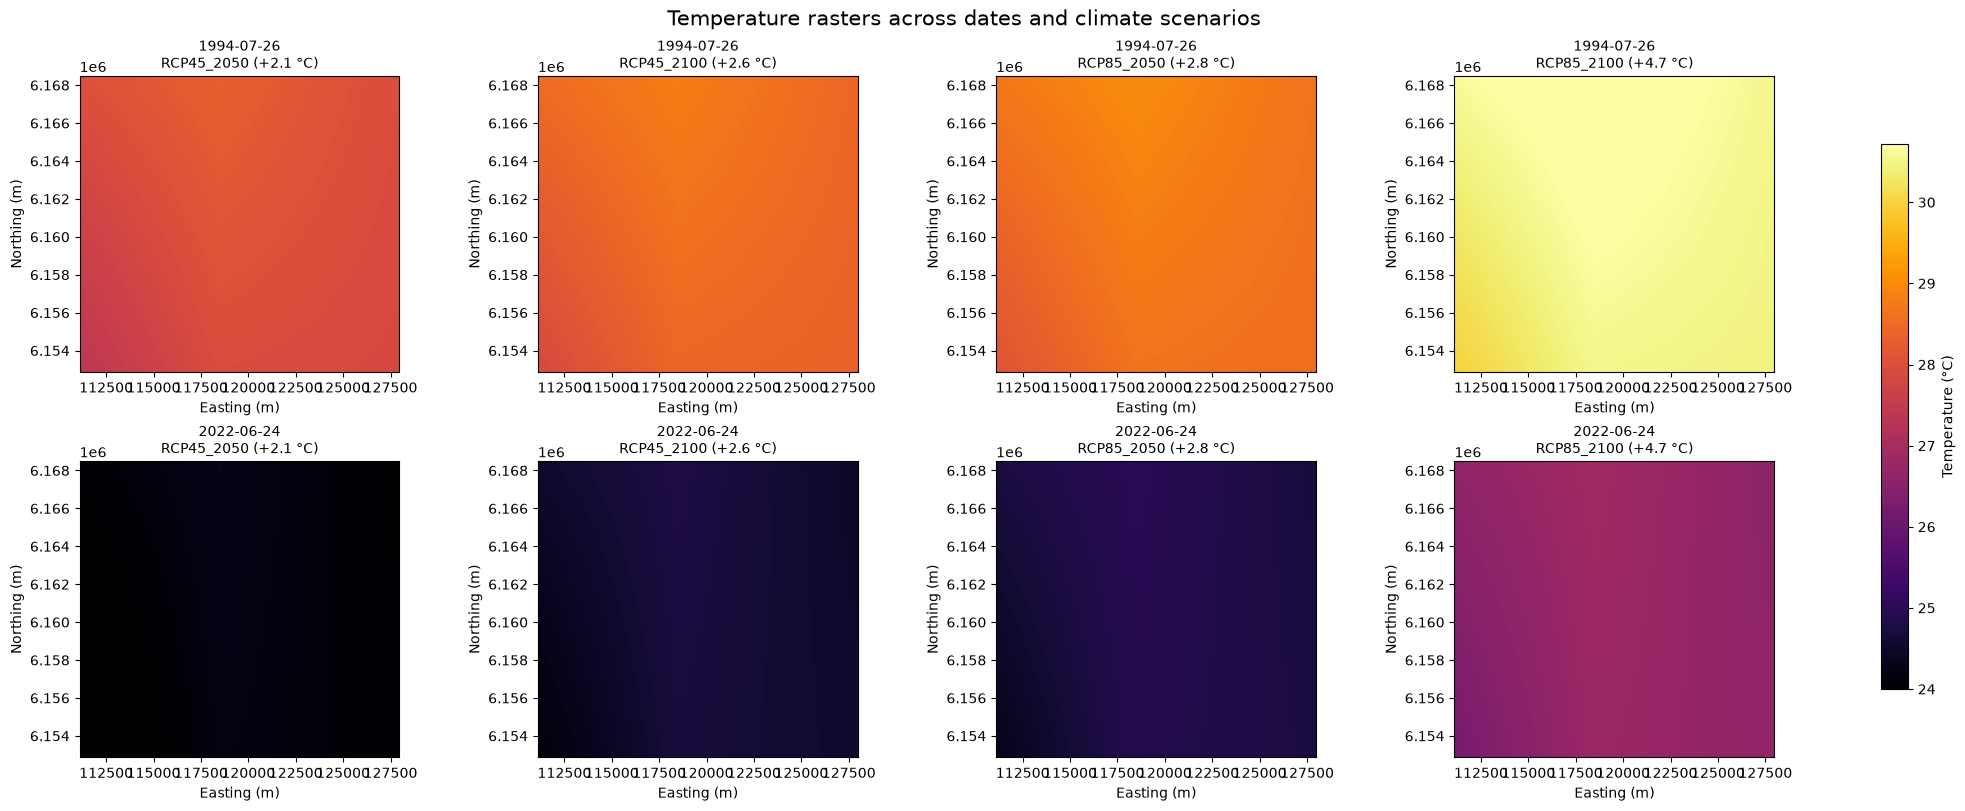

In [18]:

from pathlib import Path
import math

import numpy as np
import rasterio
import matplotlib.pyplot as plt

# Assumes DATES, ANOMALIES, and OUT_DIR are already defined.
# Example:
# DATES = ["1994-07-26", "2022-06-24"]
# ANOMALIES = {
#     "RCP45_2050": 2.1,
#     "RCP45_2100": 2.6,
#     "RCP85_2050": 2.8,
#     "RCP85_2100": 4.7,
# }

items = [
    (date, scenario, anomaly)
    for date in DATES
    for scenario, anomaly in ANOMALIES.items()
]

# Read all rasters and find a shared colour scale.
rasters = []
all_valid_values = []

for date, scenario, anomaly in items:
    output_path = OUT_DIR / f"{date}_temperature_{scenario}.tif"

    if not output_path.exists():
        print(f"Missing file: {output_path}")
        rasters.append(None)
        continue

    with rasterio.open(output_path) as src:
        data = src.read(1, masked=True).astype(np.float32)
        extent = rasterio.plot.plotting_extent(src)
        crs = src.crs
        resolution = src.res

    data = np.ma.masked_invalid(
        np.ascontiguousarray(data.filled(np.nan))
    )

    rasters.append((data, extent))

    if data.count() > 0:
        all_valid_values.append(data.compressed())

    print(
        output_path.name,
        "| anomaly:", anomaly, "°C",
        "| resolution:", resolution,
        "| CRS:", crs
    )

if not all_valid_values:
    raise ValueError("No valid temperature rasters were found.")

# Shared scale makes colours comparable between scenarios.
all_values = np.concatenate(all_valid_values)
vmin = float(np.percentile(all_values, 2))
vmax = float(np.percentile(all_values, 98))

ncols = 4
nrows = math.ceil(len(items) / ncols)

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(5 * ncols, 4 * nrows),
    constrained_layout=True
)
axes = np.asarray(axes).ravel()

image = None

for ax, item, raster in zip(axes, items, rasters):
    date, scenario, anomaly = item

    if raster is None:
        ax.set_title(f"{date} — {scenario}\nMissing raster")
        ax.axis("off")
        continue

    data, extent = raster

    image = ax.imshow(
        data,
        extent=extent,
        origin="upper",
        cmap="inferno",
        vmin=vmin,
        vmax=vmax,
        interpolation="nearest"
    )

    ax.set_title(
        f"{date}\n{scenario} (+{anomaly} °C)",
        fontsize=10
    )
    ax.set_xlabel("Easting (m)")
    ax.set_ylabel("Northing (m)")
    ax.set_aspect("equal")

# Hide any unused panels.
for ax in axes[len(items):]:
    ax.axis("off")

if image is not None:
    fig.colorbar(
        image,
        ax=axes.tolist(),
        label="Temperature (°C)",
        shrink=0.8
    )

fig.suptitle(
    "Temperature rasters across dates and climate scenarios",
    fontsize=15
)

plt.show()
